# Deep Learning 
## Neural Network Fundamentals, ML & DL Models, Tree-Based Models, CNNs, VGG and ResNet

### Learning path
1. What problem does Machine Learning solve?
2. Machine Learning vs Deep Learning
3. Understand features, labels, training and prediction
4. What is a neural network?
5. A single artificial neuron: weights, bias and activation
6. How a neural network learns: prediction, loss, gradients and updates
7. Overview of ML and DL models
8. Tree-based models: Decision Tree, Random Forest and Gradient Boosting
9. Why images need special models
10. CNN basics: filters, feature maps, stride, padding and pooling
11. VGG16 and VGG19
12. ResNet and residual connections
13. Compare models and choose a suitable one
14. Revision questions



## 0. Setup

This notebook uses:
- **NumPy** for small numerical examples
- **scikit-learn** for traditional ML models
- **Matplotlib** for simple plots
- **PyTorch** for a small CNN demonstration

If an import fails in your environment, install the missing package. In Google Colab, most of these packages are usually available already.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

print("NumPy version:", np.__version__)

NumPy version: 1.26.4


## 1. Why do we need Machine Learning?

Imagine writing a program to identify spam emails. We could write rules such as “if the email says *claim your prize*, mark it as spam.” But spammers can change their wording, and genuine emails may contain those same words.

Machine Learning (ML) takes another approach: give a model many examples and let it learn patterns from them.

### Three terms to remember
- **Example:** One row or item in a dataset.
- **Feature:** Information used to make a prediction.
- **Label/target:** The answer the model is meant to predict during supervised training.

For a student-pass prediction problem, study hours and attendance might be features, while pass/fail is the label.

## 2. AI vs ML vs Deep Learning

- **Artificial Intelligence (AI):** The broad field of making computers perform tasks that seem to require intelligence.
- **Machine Learning (ML):** A part of AI in which systems learn patterns from data.
- **Deep Learning (DL):** A part of ML that uses neural networks with multiple layers to learn representations.

So the relationship is:

**AI → ML → Deep Learning**

Not all AI uses ML, and not all ML uses deep learning.

## 3. Types of ML problems

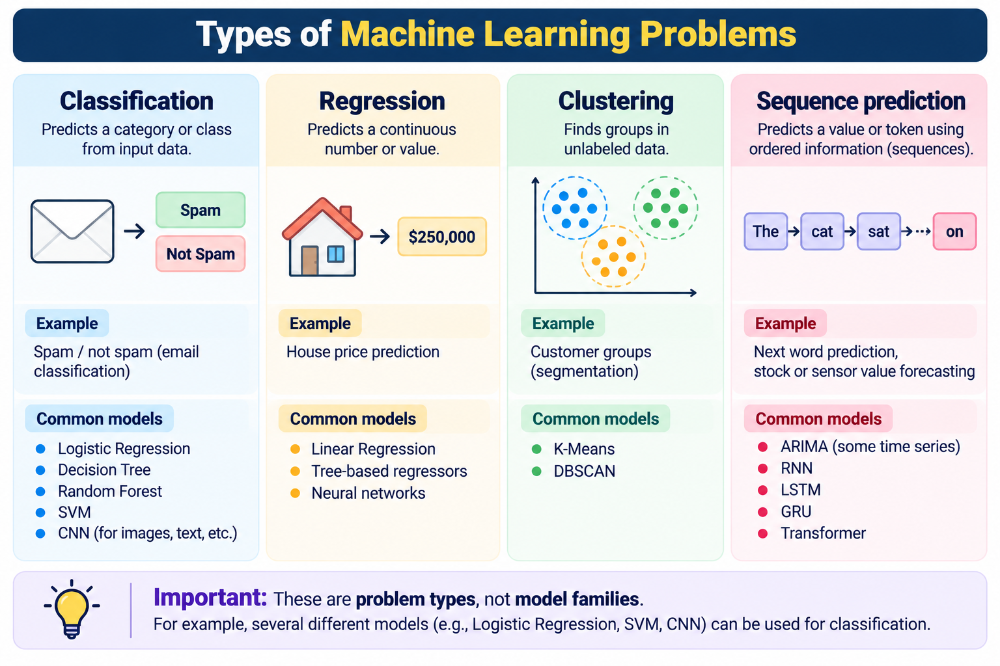

| Problem | What is predicted/discovered? | Example | Common models |
|---|---|---|---|
| Classification | A category | Spam / not spam | Logistic Regression, Decision Tree, Random Forest, SVM, CNN |
| Regression | A number | House price | Linear Regression, tree regressors, neural networks |
| Clustering | Groups in unlabeled data | Customer groups | K-Means, DBSCAN |
| Sequence prediction | A value/token using ordered information | Next word, sensor forecast | ARIMA (some time series), RNN, LSTM, GRU, Transformer |

**Important:** These are problem types, not model families. For example, several different models can perform classification.

## 4. Training, validation, testing and inference

A common workflow is:

1. **Training data:** Used to learn model parameters.
2. **Validation data:** Used to compare models and tune settings.
3. **Test data:** Kept separate for a final, fair evaluation.
4. **Inference:** Using a trained model to make predictions on new inputs.

A model should not be evaluated only on the examples it trained on. It might memorize those examples and still perform poorly on new data. This is called **overfitting**.

## 5. What is an artificial neural network?

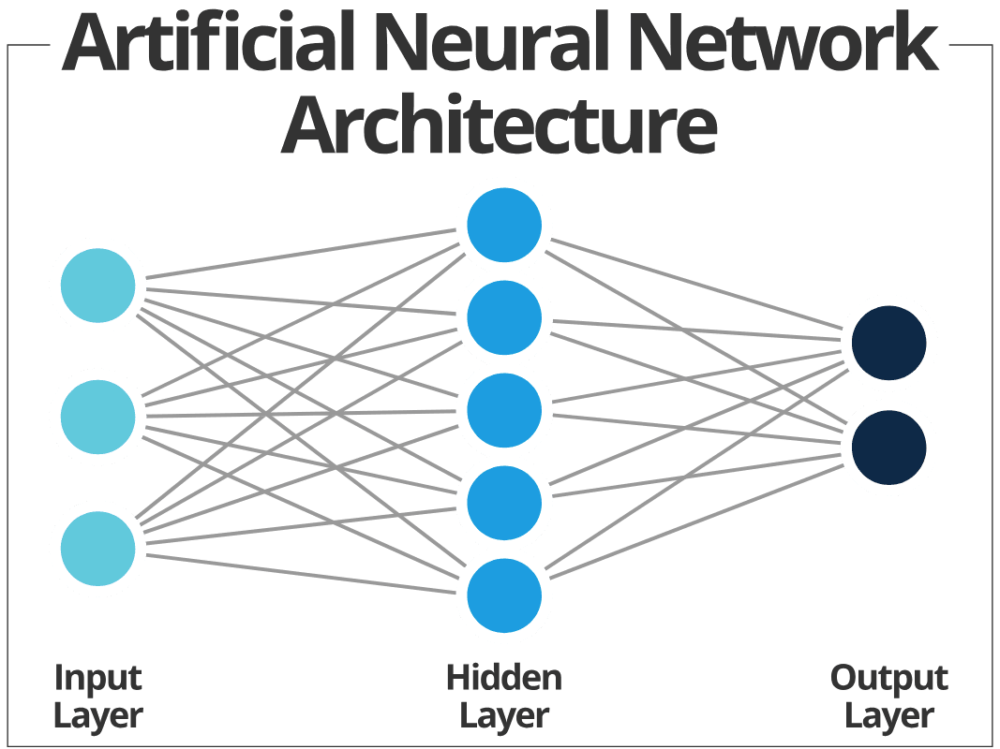

A neural network is a model made of connected computational units called **neurons**, arranged in layers.

- **Input layer:** Receives features.
- **Hidden layer(s):** Transform information and learn useful patterns.
- **Output layer:** Produces a prediction.

A network with multiple hidden layers is often called a deep neural network.

### Big idea
The network starts with adjustable parameters. During training, it changes those parameters so its predictions become more useful.

## 6. One neuron: inputs, weights, bias and activation

A simple artificial neuron calculates:


> z = W1X1 + W2X2 +.......+ WnXn + b

Then it applies an activation function:

\[
a = f(z)
\]

Where:
- \(x_i\): input features
- \(w_i\): weights that control each input's contribution
- \(b\): bias, an additional learnable parameter
- \(z\): weighted sum plus bias
- \(f\): activation function
- \(a\): neuron output

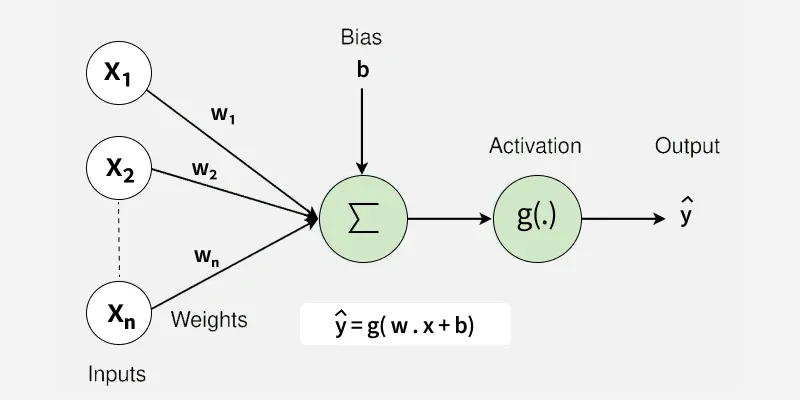

### Worked example
Let \(x_1=2\), \(x_2=3\), \(w_1=0.5\), \(w_2=0.2\), and \(b=0.1\).

Then \(z = 0.5(2) + 0.2(3) + 0.1 = 1.7\).

ReLU is defined as \(f(z)=\max(0,z)\). Because \(z=1.7\), ReLU returns 1.7.

In [ ]:
x1, x2 = 2, 3
w1, w2 = 0.5, 0.2
bias = 0.1

z = w1*x1 + w2*x2 + bias
relu_output = max(0, z)

print("Weighted sum + bias:", z)
print("ReLU output:", relu_output)

### Try changing the numbers
Change one weight or input in the cell above and run it again. Notice how the output changes. The weights and bias are parameters that training will learn.

## 7. Activation functions: why do we need them?

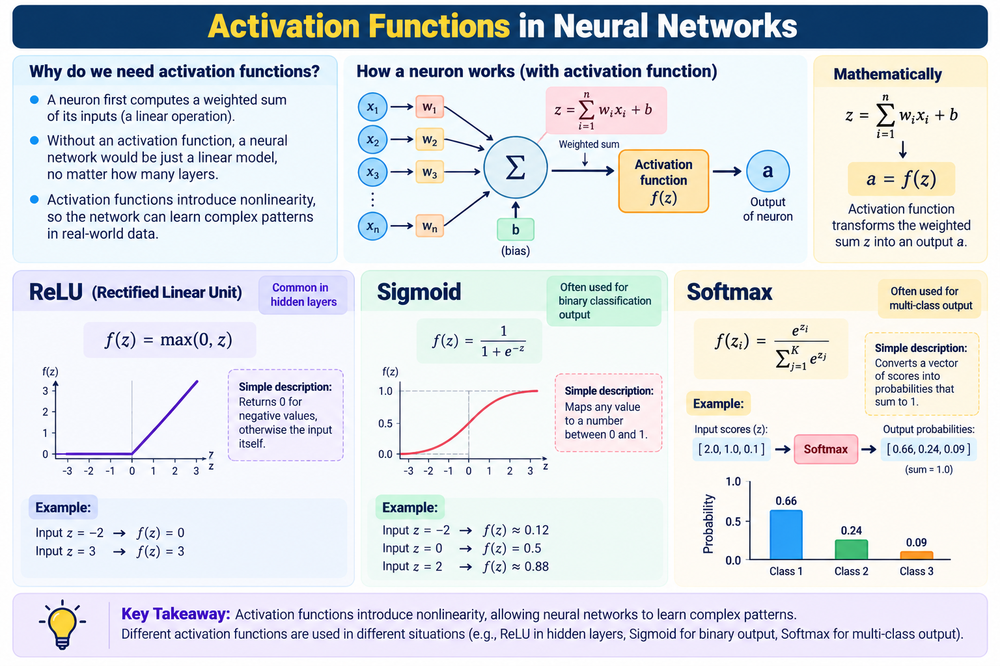

An activation function transforms a neuron's weighted sum. Hidden-layer activations allow a network to learn nonlinear relationships.

| Function | Simple description | Common use |
|---|---|---|
| ReLU | Returns 0 for negative values, otherwise the input | Common in hidden layers |
| Sigmoid | Maps a value to between 0 and 1 | Often binary-classification output |
| Softmax | Converts a vector of scores into values summing to 1 | Often multi-class output |



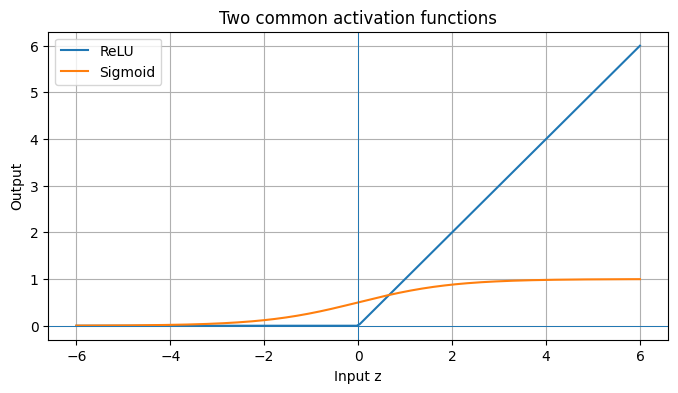

In [2]:
def relu(z):
    return np.maximum(0, z)

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

values = np.linspace(-6, 6, 200)

plt.figure(figsize=(8, 4))
plt.plot(values, relu(values), label="ReLU")
plt.plot(values, sigmoid(values), label="Sigmoid")
plt.axhline(0, linewidth=0.7)
plt.axvline(0, linewidth=0.7)
plt.title("Two common activation functions")
plt.xlabel("Input z")
plt.ylabel("Output")
plt.legend()
plt.grid(True)
plt.show()

## 8. How does a neural network learn?

A simplified training loop has four main ideas:

1. **Forward pass:** The network makes a prediction.
2. **Loss:** A loss function measures how wrong the prediction is.
3. **Backpropagation:** Calculates how the loss changes with respect to the model parameters.
4. **Optimizer update:** Uses those gradients to adjust parameters.

This process repeats over many examples and training steps.

### Key terms
- **Loss function:** Measures prediction error for training.
- **Gradient:** Tells how a small parameter change affects the loss.
- **Gradient descent:** Updates parameters in a direction that aims to reduce loss.
- **Learning rate:** Controls the size of an update.
- **Epoch:** One full pass through the training dataset (in the usual definition).
- **Backpropagation:** Efficiently computes gradients using the chain rule. It calculates gradients; the optimizer applies updates.

### A tiny gradient-descent example

Suppose a model predicts \(\hat y = wx\). We want it to predict \(y=6\) when \(x=2\). The squared error is:

\[
L=(\hat y-y)^2
\]

We will update the weight \(w\) using a gradient. This is a simplified example to demonstrate the idea, not a full neural network.

In [ ]:
x = 2.0
y_true = 6.0
w = 1.0
learning_rate = 0.1

for step in range(5):
    y_pred = w * x
    loss = (y_pred - y_true) ** 2
    gradient = 2 * (y_pred - y_true) * x  # derivative of loss with respect to w
    w = w - learning_rate * gradient
    print(f"Step {step+1}: prediction={y_pred:.3f}, loss={loss:.3f}, updated w={w:.3f}")

**What to notice:** The weight changes in response to the error. The goal of training is not to memorize this particular formula; it is to understand the loop: predict → measure error → calculate gradients → update parameters.

## 9. Overview of ML and DL model families

### Traditional ML models
- **Linear Regression:** Predicts a number using a linear relationship.
- **Logistic Regression:** A classification model that estimates class probabilities.
- **Decision Tree:** Learns feature-based rules.
- **Random Forest:** Combines many randomized decision trees.
- **Gradient Boosting:** Builds learners sequentially to improve the combined model.
- **Support Vector Machine (SVM):** Finds a separating boundary with a large margin; kernels can model nonlinear boundaries.
- **K-Nearest Neighbors (KNN):** Predicts using nearby training examples.
- **Naive Bayes:** Uses a probabilistic approach with a conditional-independence assumption.

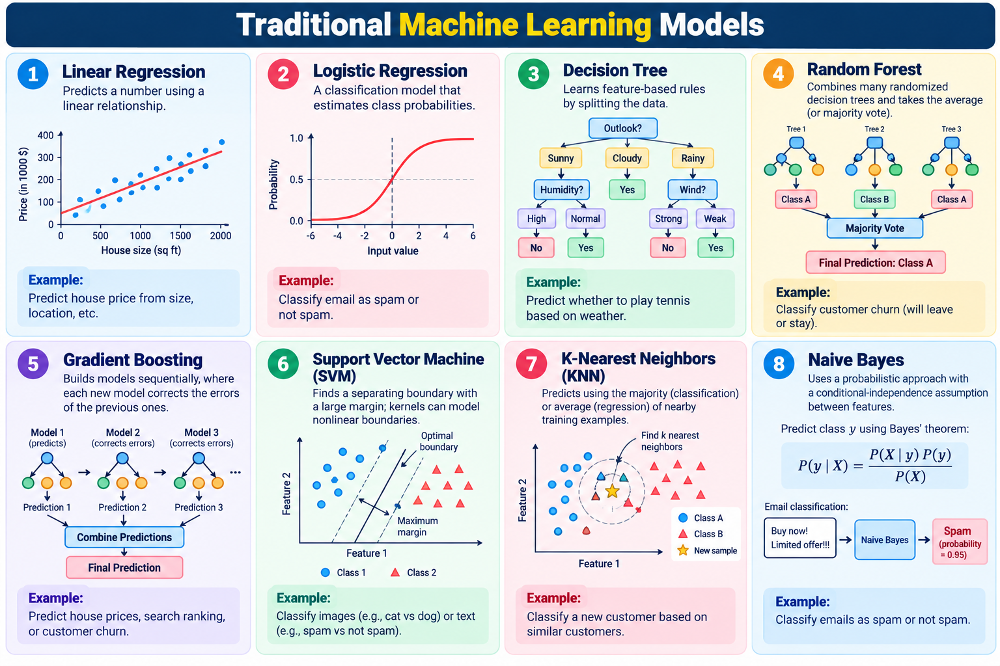

### Deep Learning models
- **MLP / Feedforward network:** General-purpose neural network, often used for tabular or vector data.
- **CNN:** Particularly useful for image-like data and local spatial patterns.
- **RNN / LSTM / GRU:** Designed to process ordered sequences.
- **Transformer:** Uses attention to process relationships between elements; used in language, vision and other domains.

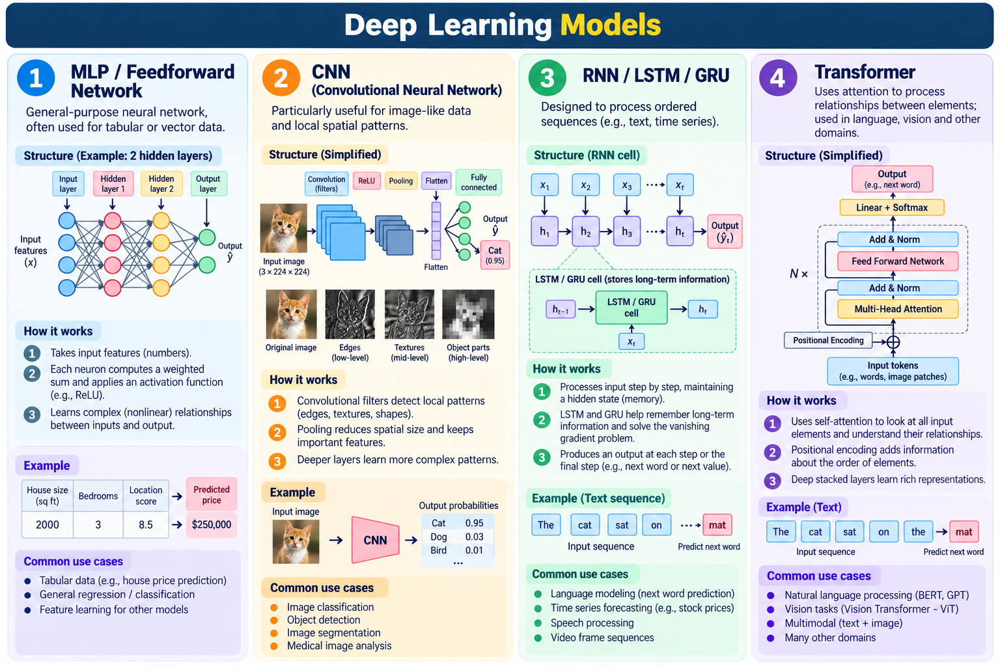

### Model choice depends on
1. What output is needed?
2. What kind of data is available?
3. How much labeled data is available?
4. What hardware and time constraints exist?
5. Which metric and practical constraints matter?
6. How do candidate models perform on validation data?

There is no single best model for every problem.

## 10. Tree-based models

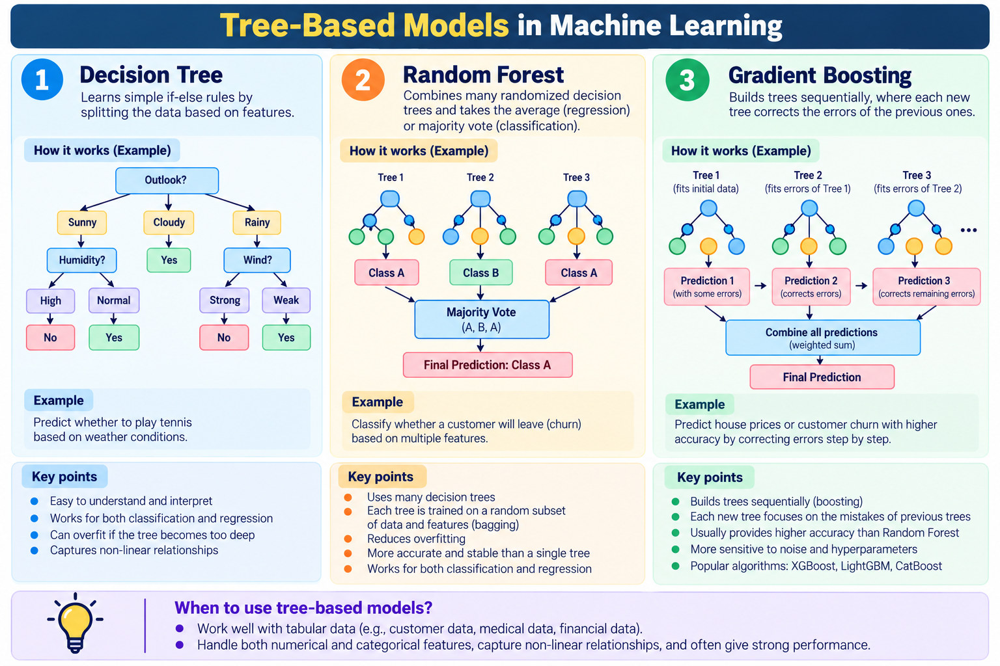

A decision tree makes predictions by asking a sequence of questions about features.

Example:
- Is attendance greater than 70%?
- Are previous marks greater than 50?
- Based on the path, predict pass or fail.

### Decision Tree
**Strengths:** Easy to explain, handles nonlinear relationships, and works with tabular features.

**Limitations:** A deep tree can overfit and small data changes may produce a different tree.

### Random Forest
Trains many trees using randomness in samples and feature selection, then combines their predictions. It often improves stability over a single tree.

### Gradient Boosting
Builds trees in sequence, where later trees aim to improve the combined model. XGBoost, LightGBM and CatBoost are popular implementations.

**Remember the difference:**
- Random Forest: bagging-style ensemble; trees are built largely independently.
- Gradient Boosting: boosting; trees are added sequentially to improve the ensemble.

### Run three tree-based models on a small example

We will use a built-in dataset and compare:
- Decision Tree
- Random Forest
- Gradient Boosting

We split the data into training and test sets. The test set is used only for this simple demonstration; in a real project, model tuning should use validation or cross-validation and reserve the test set for final evaluation.

In [3]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, classification_report

data = load_breast_cancer()
X_train, X_test, y_train, y_test = train_test_split(
    data.data, data.target, test_size=0.25, random_state=42, stratify=data.target
)

models = {
    "Decision Tree": DecisionTreeClassifier(max_depth=4, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=150, random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42)
}

for name, model in models.items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)
    print(f"{name}: accuracy = {accuracy_score(y_test, predictions):.3f}")

Decision Tree: accuracy = 0.944
Random Forest: accuracy = 0.958
Gradient Boosting: accuracy = 0.958


**Interpretation:** Accuracy is the fraction of predictions that are correct. It is useful, but it may be misleading when classes are imbalanced or error types have different costs. In research, also consider precision, recall, F1-score, confusion matrices and the consequences of false positives/false negatives.

Do not conclude that one model is universally best based on one split or one dataset.

## 11. Why CNNs for images?

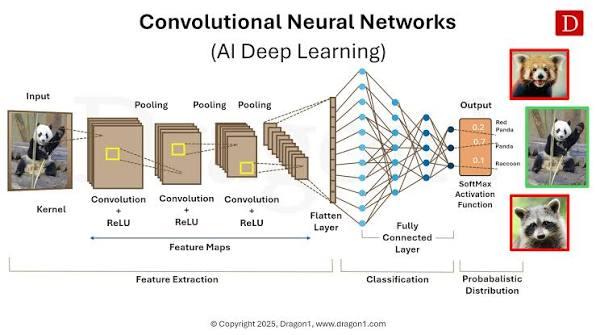

A regular fully connected neural network can process flattened image pixels, but it loses the convenient two-dimensional structure unless it learns that structure from data. It can also require a very large number of parameters.

A **Convolutional Neural Network (CNN)** uses filters that slide across an image. These filters detect local patterns, such as edges and textures, which later layers can combine into more complex visual features.

A simplified CNN pipeline:

**Image → Convolution → Activation → Pooling (optional) → More layers → Classifier → Prediction**

CNNs are especially useful when local spatial patterns matter. They are not the only models for images; Vision Transformers are another important family.

## 12. CNN vocabulary

### 12.1 Image and channels
A grayscale image can be represented as height × width, for example 28 × 28. An RGB image has three color channels, often represented as height × width × 3 (or channel-first in many deep-learning libraries).

### 12.2 Filter / kernel
A small grid of learnable numbers that slides across an image to detect patterns.

### 12.3 Convolution and feature map
At each location, the filter combines local pixel values with its weights. The resulting values form a **feature map**.

### 12.4 Stride
How many pixels the filter moves at each step. A larger stride usually produces a smaller feature map.

### 12.5 Padding
Extra border values (often zeros) added around the image. Padding can help control output size and preserve border information.

### 12.6 Pooling
A downsampling operation, such as max pooling, that reduces spatial dimensions. Pooling is common but not mandatory in every CNN.

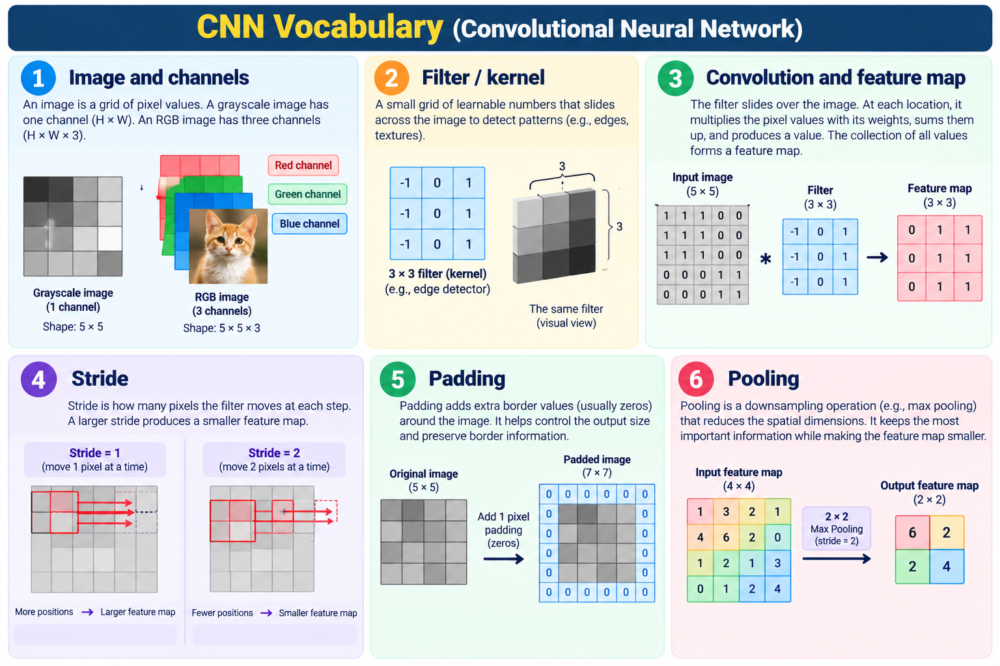

### Visualize a simple convolution

This is a tiny, hand-crafted example. Real CNN filters are usually learned during training rather than manually specified.

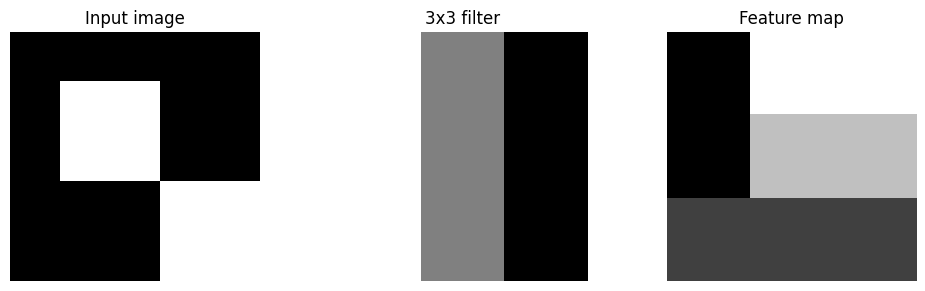

Feature map shape: (3, 3)
[[-2.  2.  2.]
 [-2.  1.  1.]
 [-1. -1. -1.]]


In [4]:
# A tiny 5x5 grayscale image
image = np.array([
    [0, 0, 0, 0, 0],
    [0, 1, 1, 0, 0],
    [0, 1, 1, 0, 0],
    [0, 0, 0, 1, 1],
    [0, 0, 0, 1, 1]
], dtype=float)

# A simple 3x3 filter (kernel)
kernel = np.array([
    [1, 0, -1],
    [1, 0, -1],
    [1, 0, -1]
], dtype=float)

# Valid convolution-like operation (cross-correlation as used by most CNN libraries)
out_h = image.shape[0] - kernel.shape[0] + 1
out_w = image.shape[1] - kernel.shape[1] + 1
feature_map = np.zeros((out_h, out_w))

for i in range(out_h):
    for j in range(out_w):
        region = image[i:i+3, j:j+3]
        feature_map[i, j] = np.sum(region * kernel)

fig, axes = plt.subplots(1, 3, figsize=(10, 3))
axes[0].imshow(image, cmap="gray")
axes[0].set_title("Input image")
axes[1].imshow(kernel, cmap="gray")
axes[1].set_title("3x3 filter")
axes[2].imshow(feature_map, cmap="gray")
axes[2].set_title("Feature map")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

print("Feature map shape:", feature_map.shape)
print(feature_map)

## 13. Output size: stride and padding

For a 1D dimension, the common convolution output-size formula is:

\[
\text{output size} =
\left\lfloor \frac{N + 2P - K}{S} \right\rfloor + 1
\]

Where:
- \(N\): input size
- \(K\): kernel size
- \(P\): padding
- \(S\): stride

For example, input size 32, kernel size 3, padding 1, stride 1:

\[
\left\lfloor \frac{32 + 2(1) - 3}{1} \right\rfloor + 1 = 32
\]

So the output dimension remains 32.

In [5]:
import math

N, K, P, S = 32, 3, 1, 1
output_size = math.floor((N + 2*P - K) / S) + 1
print("Output dimension:", output_size)

Output dimension: 32


## 14. A small CNN using PyTorch

This section defines a small CNN and passes a batch of fake images through it. Random images are used only to demonstrate tensor shapes; this does **not** train a useful image classifier.

Typical PyTorch image batches use shape:
`(batch_size, channels, height, width)`.

In [6]:
try:
    import torch
    import torch.nn as nn

    class SmallCNN(nn.Module):
        def __init__(self, num_classes=10):
            super().__init__()
            self.features = nn.Sequential(
                nn.Conv2d(1, 8, kernel_size=3, padding=1),
                nn.ReLU(),
                nn.MaxPool2d(kernel_size=2),
                nn.Conv2d(8, 16, kernel_size=3, padding=1),
                nn.ReLU(),
                nn.MaxPool2d(kernel_size=2)
            )
            self.classifier = nn.Sequential(
                nn.Flatten(),
                nn.Linear(16 * 7 * 7, 32),
                nn.ReLU(),
                nn.Linear(32, num_classes)
            )

        def forward(self, x):
            x = self.features(x)
            return self.classifier(x)

    model = SmallCNN(num_classes=10)
    fake_images = torch.randn(4, 1, 28, 28)  # 4 grayscale images, 28x28
    output = model(fake_images)

    print("Input shape:", fake_images.shape)
    print("Output shape:", output.shape)
    print("Output has 10 scores per image, one for each class.")
except ImportError:
    print("PyTorch is not installed. Install torch to run this section.")

Input shape: torch.Size([4, 1, 28, 28])
Output shape: torch.Size([4, 10])
Output has 10 scores per image, one for each class.


### Follow the shapes
- Input: `(4, 1, 28, 28)` — 4 images, 1 channel, 28 × 28 pixels.
- First convolution: 8 feature maps per image; padding preserves 28 × 28.
- First max pool: halves spatial size to 14 × 14.
- Second convolution: 16 feature maps at 14 × 14.
- Second max pool: halves to 7 × 7.
- Flatten: each image becomes 16 × 7 × 7 = 784 numbers.
- Final layer: returns 10 scores per image.

The 10 outputs are class scores (logits), not probabilities by themselves. A softmax can convert them to normalized class probabilities when appropriate.

## 15. VGG architectures

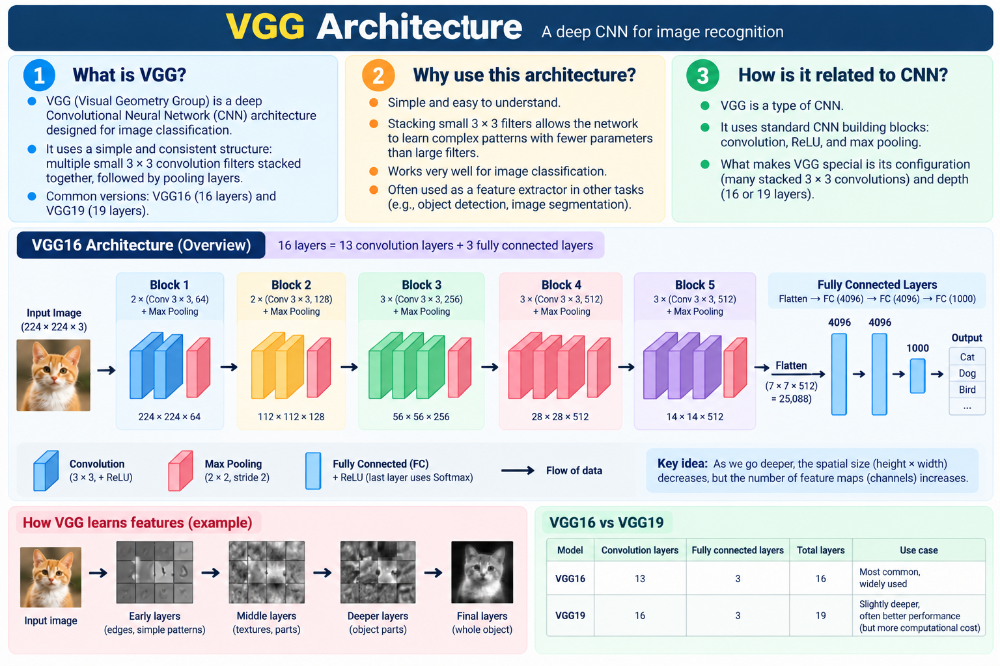

VGG is a family of CNN architectures known for a simple, repeated design: stacks of small 3 × 3 convolution filters, commonly followed by max pooling, and then classification layers.

### VGG16
- Commonly described as having 16 learnable weight layers: 13 convolutional layers and 3 fully connected layers.
- Uses repeated 3 × 3 convolutions and max-pooling stages.
- Has a relatively simple and regular design.
- The original classifier is large and has many parameters.

### VGG19
- Commonly described as having 19 learnable weight layers: 16 convolutional layers and 3 fully connected layers.
- Follows a similar design but has more convolutional layers than VGG16.

### Why use VGG?
It is a clear architecture for learning CNN concepts and has historically been useful as a pretrained image-feature extractor.

### Limitations
VGG models can be computationally expensive and parameter-heavy, especially compared with more modern architectures.

**Memory aid:** VGG16 = 13 convolutional + 3 fully connected layers. VGG19 = 16 convolutional + 3 fully connected layers. The number refers to learnable weight layers, not every activation or pooling operation.

## 16. ResNet: why residual connections matter

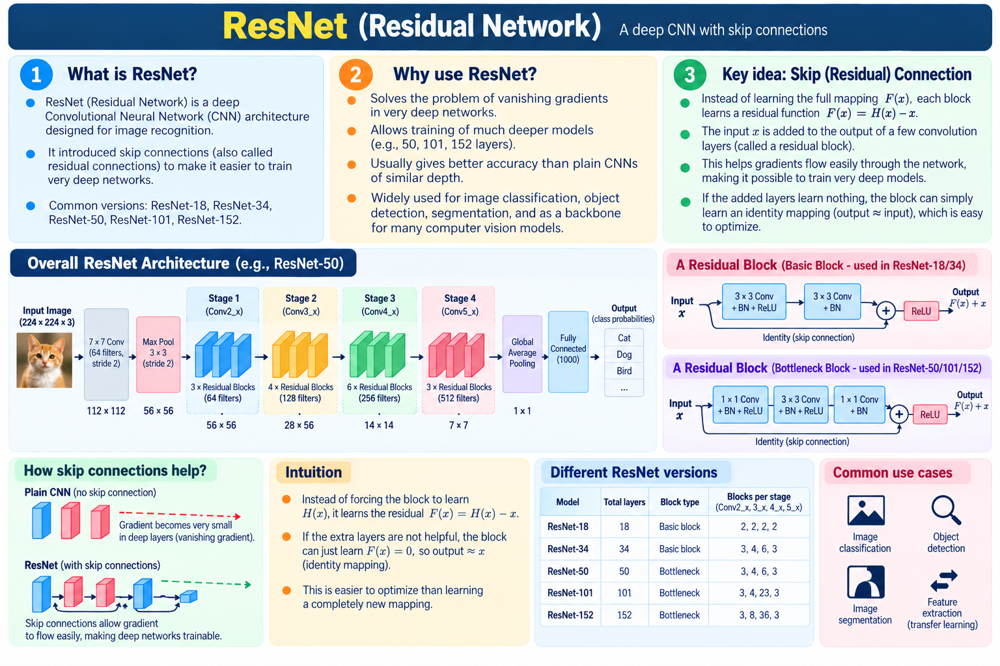

As neural networks get deeper, training can become difficult. ResNet (Residual Network) introduced residual blocks that provide a shortcut connection around some layers.

A typical residual block computes:

\[
y = F(x) + x
\]

- \(x\): input to the block
- \(F(x)\): transformation learned by the convolutional layers
- \(+x\): shortcut or skip connection
- \(y\): block output

If dimensions differ, the shortcut may use a projection (often a 1 × 1 convolution) to make the dimensions compatible.

### Intuition
Instead of forcing stacked layers to learn a complete transformation from scratch, a residual block learns a change \(F(x)\) to add to the input. The shortcut also gives gradients a more direct path through the network.

Residual connections help train very deep networks; they do not guarantee that every deeper model will always perform better.

In [ ]:
# A numerical illustration of a residual addition (not a trained neural network)
x = np.array([1.0, 2.0, 3.0])
F_x = np.array([0.2, -0.5, 1.0])

y = F_x + x

print("Input x:", x)
print("Learned transformation F(x):", F_x)
print("Residual output y = F(x) + x:", y)

### ResNet-18
ResNet-18 is a commonly used 18-layer residual network. Its standard design uses basic residual blocks and is often a useful starting point for image-classification tasks.

### ResNet compared with VGG
- **VGG:** Repeated convolution and pooling blocks; straightforward but often parameter-heavy.
- **ResNet:** Adds shortcut connections; designed to make deeper networks easier to optimize.
- Both can be used as pretrained models and fine-tuned for new image tasks.

## 17. Transfer learning: using a pretrained CNN

Training a large image model from scratch can require a large labeled dataset and substantial compute.

**Transfer learning** starts with a model trained on a source task/dataset and reuses its learned representations for a related task.

Two common approaches:
1. **Feature extraction:** Freeze most or all of the pretrained backbone and train a new classifier.
2. **Fine-tuning:** Unfreeze some or all pretrained layers and train them carefully on the new dataset, often with a smaller learning rate.

### Example
A CNN pretrained on a large image dataset may already detect edges, textures and shapes. For a smaller dataset of plant diseases, you can replace its final classification layer and train for the new classes.

### Important caution
Pretraining helps when the source representations transfer to the target task. It is not a guarantee of success; data quality, domain differences and evaluation still matter.

## 18. How should you choose between tree models and CNNs?

| Question | Tree-based models often make sense when… | CNNs often make sense when… |
|---|---|---|
| Data format | Data is tabular: rows and columns | Data is image-like or spatial |
| Features | Columns are meaningful measurements | Useful patterns can be learned from pixels |
| Data volume | Small-to-medium structured datasets may be enough | Deep image learning often benefits from substantial data or pretraining |
| Interpretation | Individual tree rules may be inspected | Learned representations are usually less directly interpretable |
| Baselines | Random Forest / boosting are strong tabular baselines | A pretrained CNN is a common image baseline |

These are practical starting points, not strict laws. Compare candidates fairly using a validation set, suitable metrics, and the same data split.

## 19. Quick revision sheet

- **AI:** Broad field of intelligent systems.
- **ML:** Learns patterns from data.
- **DL:** ML using multilayer neural networks.
- **Feature:** Input used by the model.
- **Label:** Target answer in supervised learning.
- **Weight:** Controls the contribution of an input.
- **Bias:** Additional learnable parameter.
- **Activation:** Transforms a neuron's weighted sum.
- **Loss:** Measures prediction error.
- **Backpropagation:** Computes gradients of the loss.
- **Gradient descent:** Updates parameters using gradients.
- **Decision Tree:** Makes predictions using feature-based splits.
- **Random Forest:** Combines many randomized trees.
- **Gradient Boosting:** Adds learners sequentially to improve the ensemble.
- **CNN:** Uses convolution filters to learn local patterns.
- **Feature map:** Output produced by applying a filter across an input.
- **Pooling:** Reduces spatial dimensions.
- **VGG16:** 13 convolutional + 3 fully connected learnable layers.
- **VGG19:** 16 convolutional + 3 fully connected learnable layers.
- **ResNet:** Uses residual/skip connections, commonly expressed as \(y=F(x)+x\).
- **Transfer learning:** Reuses knowledge from a pretrained model.
- **Overfitting:** Performs well on training data but generalizes poorly.

## 20. Self-test questions

Try answering these without looking at the revision sheet.

1. Explain the difference between ML and DL.
2. What is the difference between a feature and a label?
3. What are weights and bias in a neuron?
4. Why do neural networks use activation functions?
5. What is the difference between loss and an optimizer?
6. What does backpropagation calculate?
7. How does a Decision Tree make a prediction?
8. What is the main difference between Random Forest and Gradient Boosting?
9. Why are CNNs well suited to image data?
10. What are a filter and a feature map?
11. What does pooling do?
12. How do VGG16 and VGG19 differ?
13. What problem do residual connections address in ResNet?
14. What is the difference between feature extraction and fine-tuning?
15. If you have a tabular dataset and an image dataset, why might you start with different model families?

### Suggested study method
1. Read one section.
2. Run its code cell.
3. Explain the concept aloud in your own words.
4. Answer the related questions without notes.
5. Revisit any topic you cannot explain simply.